# 02: Results Analysis

**Project:** Concept-Drift-Aware Credit-Card Fraud Detection Using Online, Imbalance-Aware Classical ML

This notebook pulls every experiment together and answers the three synopsis objectives. It runs no
models: it reads the result files written by the experiment scripts, so every number below can be
traced to a CSV in `results/`. To regenerate them (from the project root, with the venv active):

```
python experiments/run_experiment.py                                                       # synthetic
python experiments/run_experiment.py --data data/raw/creditcard.csv --batch-size 10000
python experiments/run_experiment.py --data data/raw/creditcard.csv --batch-size 10000 --inject-drift 0.5
python experiments/run_imbalance.py  [same three variants]
python experiments/run_reported_vs_deployed.py  [same three variants]
```

| Dataset tag | What it is | Known drift |
|---|---|---|
| `synthetic` | 50,000 generated transactions, 1% fraud, batches of 2,000 | abrupt, at 50% (batch 12.5) |
| `creditcard_drift50` | ULB, features swapped from 50% on, batches of 10,000 | abrupt, at 50% (batch 14.2) |
| `creditcard` | ULB as recorded (48 hours), batches of 10,000 | none known |

**Strategies compared** (for each base model): `base` (static models: trained once and frozen;
online models: learn every transaction), `periodic retrain` (refit every 3 batches on the last 6),
`+ ADWIN` / `+ DDM` (refit on the alarm batch when the detector fires), and `+ ADWIN + accumulate`
(our method: after an alarm keep refitting on every new batch until 6 have been gathered).

In [1]:
import sys, tempfile
sys.path.insert(0, "..")

import math
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.evaluation.drift_metrics import drift_response_table, trend_per_10_batches
from src.viz.plots import (plot_grouped_bars, plot_metric_over_time, plot_reported_vs_deployed,
                           plot_summary)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
R = "../results"
DATASETS = {
    "synthetic": {"label": "Synthetic", "drift_batch": 0.5 * 50_000 / 2_000, "drift_pct": 50},
    "creditcard_drift50": {"label": "ULB + injected drift", "drift_batch": 0.5 * 284_807 / 10_000, "drift_pct": 50},
    "creditcard": {"label": "ULB as recorded", "drift_batch": None, "drift_pct": None},
}


def load_runs(tag):
    # the summary lists exactly this dataset's runs ("creditcard_*" files also match the drift50 tag)
    summary = pd.read_csv(f"{R}/{tag}_summary.csv")
    runs = pd.concat([pd.read_csv(f"{R}/{tag}_{name}.csv") for name in summary["model_name"]], ignore_index=True)
    return summary, runs


def show(plot_fn, *args, **kwargs):
    # the plotting functions write PNG files; render to a temp file and display it here
    path = tempfile.NamedTemporaryFile(suffix=".png", delete=False).name
    plot_fn(*args, out_path=path, **kwargs)
    display(Image(path))


data = {tag: load_runs(tag) for tag in DATASETS}
for tag, (summary, runs) in data.items():
    print(f"{tag:20s} {len(summary):2d} runs x {runs['batch_idx'].nunique()} evaluated batches")

synthetic            21 runs x 23 evaluated batches
creditcard_drift50   21 runs x 27 evaluated batches
creditcard           21 runs x 27 evaluated batches


## Objective 1: Baselines and imbalance-aware evaluation

> *Establish classical baselines (logistic regression, random forest, gradient boosting) and evaluate them
> with imbalance-aware metrics (PR-AUC, recall at a fixed precision, false-positive rate) rather than accuracy.*

### 1.1 Static baselines on ULB as recorded
Each model is trained on the first 2 batches (20,000 transactions) and then frozen; scores are averaged over
the 27 later batches.

In [2]:
summary, runs = data["creditcard"]
static = summary[(summary["strategy"] == "base") & summary["family"].str.contains("static")]
table = static.set_index("model_name")[["mean_pr_auc", "mean_recall_at_p", "mean_fpr", "runtime_s"]].copy()
table["mean_fpr"] = 100 * table["mean_fpr"]
fraud_rate = 492 / 284_807
table["PR-AUC vs random ranking"] = table["mean_pr_auc"] / fraud_rate
table.columns = ["PR-AUC", "recall at 90% precision", "FPR at that threshold (%)", "runtime (s)", "PR-AUC / fraud rate"]
table.round(3)

,PR-AUC,recall at 90% precision,FPR at that threshold (%),runtime (s),PR-AUC / fraud rate
model_name,,,,,
logreg,0.429,0.203,0.004,0.3,248.507
random_forest,0.760,0.628,0.007,2.3,439.928
gradient_boosting,0.542,0.360,0.003,3.3,313.602


**Interpretation**

- **Random forest is the strongest static baseline**: PR-AUC 0.760, about 440× better than a random ranking
  (whose PR-AUC equals the 0.17% fraud rate). At the 90%-precision threshold it catches 63% of fraud while
  flagging only 0.007% of legitimate transactions.
- Gradient boosting (0.542) and logistic regression (0.429) are clearly weaker. Each was trained on just 20,000
  transactions (about 85 frauds), which favours the forest's averaging of many trees.
- None of this could be seen with accuracy: every model, and the useless "always legitimate" rule, is above
  99.8% accurate.

### 1.2 How reachable is "recall at 90% precision" per batch?
`recall_at_p` is 0 whenever no score threshold reaches 90% precision in a batch. With ~13 frauds per batch,
one legitimate transaction among the top-scored ones is enough to make it unreachable. Tied top scores make it
worse: a confident logistic regression outputs exactly 1.0 for many transactions, and tied transactions
can't be separated by any threshold.

In [3]:
rows = []
for tag in DATASETS:
    summary, runs = data[tag]
    unreachable = runs.assign(none=np.isinf(runs["threshold"])).groupby("model_name")["none"].mean()
    for name in ["logreg", "random_forest", "gradient_boosting", "online_logreg", "online_arf"]:
        rows.append({"dataset": DATASETS[tag]["label"], "model": name,
                     "batches where 90% precision is unreachable (%)": 100 * unreachable[name]})
pd.DataFrame(rows).pivot(index="model", columns="dataset",
                         values="batches where 90% precision is unreachable (%)").round(0)

dataset,Synthetic,ULB + injected drift,ULB as recorded
model,,,
gradient_boosting,52.0,48.0,19.0
logreg,57.0,74.0,44.0
online_arf,9.0,15.0,11.0
online_logreg,9.0,41.0,30.0
random_forest,52.0,44.0,4.0


**Interpretation**

Per batch, recall at 90% precision is a harsh metric. On the drifting datasets, 90% precision is unreachable in
roughly half of the batches for every static model (44–74%), and the metric then reads 0, even when the model
ranks fraud well. On ULB as recorded it ranges from 4% (random forest) to 44% (logistic regression). Two causes:
1. **Few frauds per batch** (median 13 on ULB): a single legitimate transaction among the top scores can push
   precision below 90%.
2. **Tied top scores**: a confident logistic regression outputs exactly 1.0 for many transactions. In one test,
   81 transactions tied at 1.0, of which 68 were fraud (84% precision), so no threshold could reach 90%.

That's why **PR-AUC is the headline metric** in this project, with recall at 90% precision reported alongside
it as a stricter, noisier view. The online adaptive random forest rarely hits the problem (9–15% of batches)
because its scores are finer-grained.

### 1.3 Imbalance handling
Static models with no handling, class weights, SMOTE or undersampling (resampling only on training data).
Shown for the frozen model (`base`) and with our adaptive strategy (`+ ADWIN + accumulate`).

In [4]:
tables = {}
for tag in DATASETS:
    imb = pd.read_csv(f"{R}/{tag}_imbalance_summary.csv")
    tables[DATASETS[tag]["label"]] = imb.pivot_table(index=["strategy", "family"], columns="imbalance",
                                                     values="mean_pr_auc", sort=False)
imbalance = pd.concat(tables, names=["dataset"])[["no handling", "class weights", "SMOTE", "undersampling"]]
imbalance["best"] = imbalance.idxmax(axis=1)
imbalance.round(3)

imbalance                                                      no handling  class weights  SMOTE  undersampling           best
dataset              strategy             family                                                                              
Synthetic            base                 Logistic regression        0.372          0.297  0.334          0.269    no handling
                                          Random forest              0.368          0.352  0.320          0.337    no handling
                                          Gradient boosting          0.373          0.349  0.325          0.281    no handling
                     + ADWIN + accumulate Logistic regression        0.782          0.704  0.747          0.668    no handling
                                          Random forest              0.697          0.704  0.704          0.733  undersampling
                                          Gradient boosting          0.713          0.729  0.715          0.661  class weights
ULB + injected drift base                 Logistic regression        0.198          0.226  0.205          0.239  undersampling
                                          Random forest              0.432          0.475  0.409          0.436  class weights
                                          Gradient boosting          0.359          0.315  0.349          0.304    no handling
                     + ADWIN + accumulate Logistic regression        0.461          0.521  0.380          0.373  class weights
                                          Random forest              0.708          0.745  0.739          0.573  class weights
                                          Gradient boosting          0.455          0.610  0.696          0.601          SMOTE
ULB as recorded      base                 Logistic regression        0.236          0.429  0.346          0.455  undersampling
                                          Random forest              0.702          0.760  0.760          0.692          SMOTE
                                          Gradient boosting          0.625          0.542  0.565          0.609    no handling
                     + ADWIN + accumulate Logistic regression        0.496          0.429  0.346          0.455    no handling
                                          Random forest              0.702          0.760  0.760          0.692          SMOTE
                                          Gradient boosting          0.625          0.542  0.565          0.609    no handling

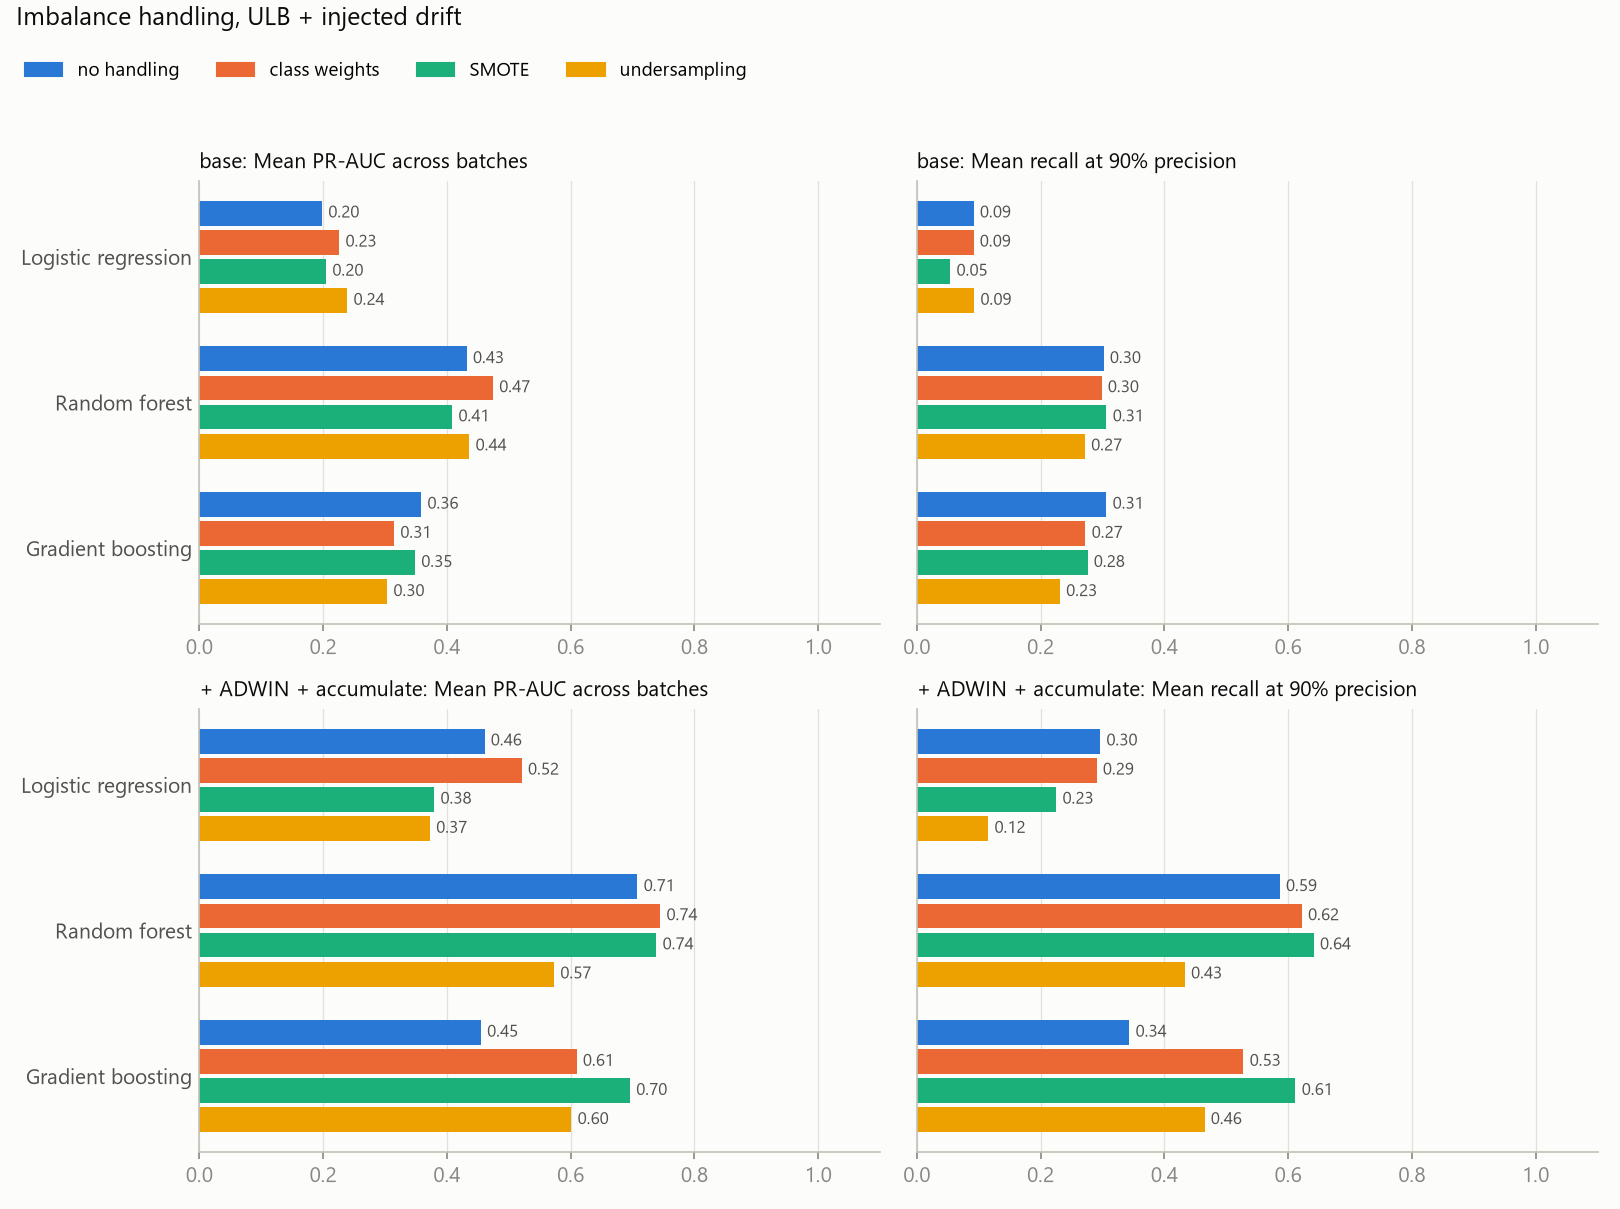

In [5]:
show(plot_grouped_bars, pd.read_csv(f"{R}/creditcard_drift50_imbalance_summary.csv"),
     metrics=["mean_pr_auc", "mean_recall_at_p"], title="Imbalance handling, ULB + injected drift")

In [6]:
imb = pd.read_csv(f"{R}/creditcard_drift50_imbalance_summary.csv")
imb.pivot_table(index="family", columns="imbalance", values="runtime_s",
                aggfunc="sum")[["no handling", "class weights", "SMOTE", "undersampling"]].round(1)

imbalance,no handling,class weights,SMOTE,undersampling
family,,,,
Gradient boosting,4.9,51.8,7.6,2.3
Logistic regression,3.4,4.5,5.2,2.4
Random forest,44.3,31.2,42.5,9.4


**Interpretation**

- **No method wins everywhere**; it depends on the model and the data.
- **On real ULB data, handling imbalance matters.** Frozen logistic regression on ULB as recorded scores 0.236
  with no handling vs 0.429 with class weights and 0.455 with undersampling. With 578 legitimate transactions
  per fraud, an unbalanced linear model mostly learns to say "legitimate".
- **For the best adaptive setup** (`+ ADWIN + accumulate`, ULB with drift), **class weights are best for logistic
  regression (0.521) and random forest (0.745)**, and **SMOTE for gradient boosting (0.696 vs 0.455 with no
  handling)**. After a drift alarm, the model retrains on only a few batches of new data, and SMOTE's synthetic
  frauds help gradient boosting most when real frauds are that scarce.
- **Undersampling is the cheapest** (random forest 9.4s vs 31–44s) **but the weakest after drift** (random forest
  0.573): throwing away data hurts when post-drift examples are already few.
- **On synthetic data, "no handling" is often best**: fraud is 6× more common (1%) and far easier to separate,
  so there is less to correct, and re-weighting mostly adds noise.
- Class weights remain the project default: simple, no change to the data, and best or tied-best for 2 of the 3
  models on real data.

## Objective 2: Time-ordered evaluation; static vs periodic vs online

> *Implement a prequential (test-then-train) evaluation over a time-ordered stream and compare a static model,
> a periodically retrained model and an online incrementally updated model, quantifying how detection
> performance degrades over time.*

### 2.1 Reported vs deployed: why shuffled evaluation misleads
A developer has the earliest 40% of the stream, reports a test score, and deploys the model unchanged.
"Reported" scores come from a random (shuffled) 70/30 split, or a time-ordered 70/30 split, of that 40%;
"deployed" scores are measured on each later 10% of the stream.

In [7]:
rows = {}
for tag in DATASETS:
    raw = pd.read_csv(f"{R}/{tag}_reported_vs_deployed.csv")
    rep = raw[raw["evaluation"] != "deployed"].groupby(["family", "evaluation"])["pr_auc"].mean().unstack()
    dep = raw[raw["evaluation"] == "deployed"]
    drift_pct = DATASETS[tag]["drift_pct"]
    if drift_pct is not None:
        rep["deployed, before drift"] = dep[dep["end_pct"] <= drift_pct].groupby("family")["pr_auc"].mean()
        rep["deployed, after drift"] = dep[dep["start_pct"] >= drift_pct].groupby("family")["pr_auc"].mean()
    else:
        rep["deployed, all later data"] = dep.groupby("family")["pr_auc"].mean()
    rows[DATASETS[tag]["label"]] = rep
reported_vs_deployed = pd.concat(rows, names=["dataset"])
reported_vs_deployed.round(3)

evaluation                                reported, random split  reported, time-ordered split  deployed, before drift  deployed, after drift  deployed, all later data
dataset              family                                                                                                                                            
Synthetic            Gradient boosting                     0.697                         0.741                   0.690                  0.034                       NaN
                     Logistic regression                   0.828                         0.738                   0.797                  0.010                       NaN
                     Random forest                         0.771                         0.730                   0.769                  0.014                       NaN
ULB + injected drift Gradient boosting                     0.717                         0.729                   0.745                  0.005                       NaN
                     Logistic regression                   0.673                         0.710                   0.734                  0.004                       NaN
                     Random forest                         0.888                         0.813                   0.715                  0.069                       NaN
ULB as recorded      Gradient boosting                     0.717                         0.729                     NaN                    NaN                     0.726
                     Logistic regression                   0.673                         0.710                     NaN                    NaN                     0.726
                     Random forest                         0.888                         0.813                     NaN                    NaN                     0.765

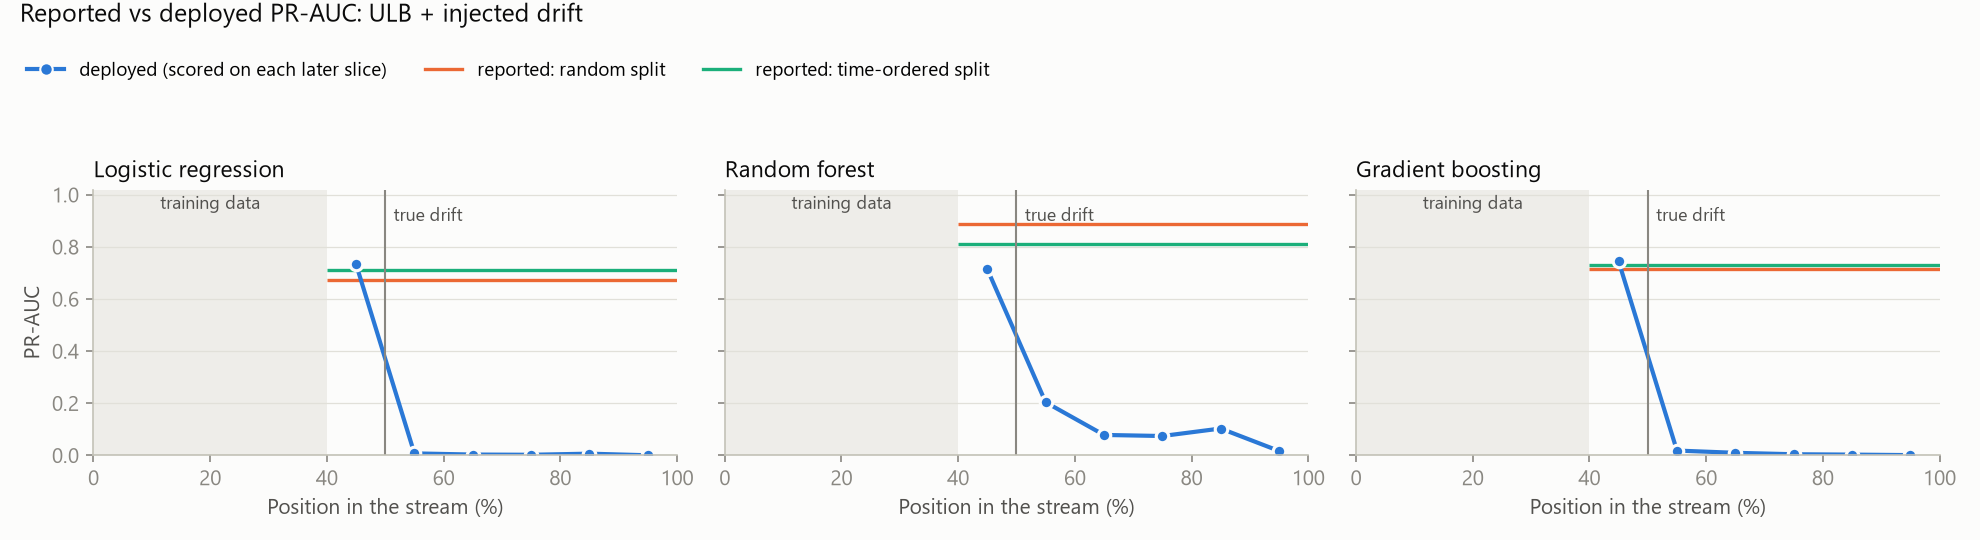

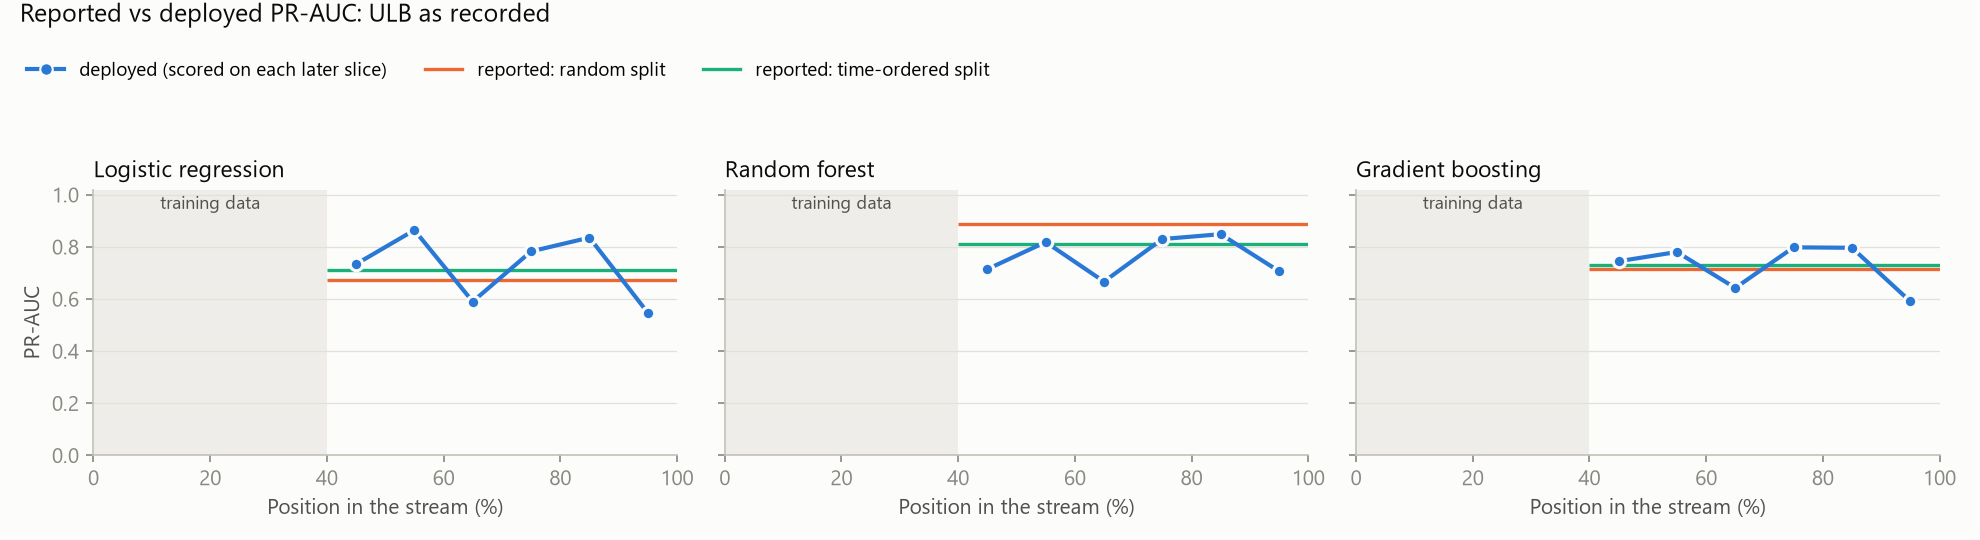

In [8]:
for tag in ["creditcard_drift50", "creditcard"]:
    raw = pd.read_csv(f"{R}/{tag}_reported_vs_deployed.csv")
    show(plot_reported_vs_deployed, raw, train_pct=40, drift_pct=DATASETS[tag]["drift_pct"],
         title=f"Reported vs deployed PR-AUC: {DATASETS[tag]['label']}")

**Interpretation: the synopsis's central claim, confirmed**

- **With drift, the reported score hides the collapse.** On ULB with injected drift, the developer would report a
  PR-AUC of **0.67–0.89** (shuffled split) or 0.71–0.81 (time-ordered split). After deployment, the models hold
  that level until the drift (0.72–0.75), then fall to **0.004–0.069**, a loss of over 90%. Nothing in the
  reported number warns of this; the synthetic stream shows the same pattern (0.70–0.83 reported, 0.01–0.03
  after the drift).
- **Without drift, the reported score is roughly right.** On ULB as recorded, the deployed scores (0.73–0.77)
  stay close to the reported ones. The shuffled split is the more optimistic of the two for random forest
  (0.888 vs 0.765 deployed; time-ordered: 0.813). A likely cause: a random split puts near-identical
  transactions (including some of the 1,081 exact duplicates) on both sides, which a forest can memorise.
- **Lesson:** a one-off test score, shuffled or not, describes the past. Only time-ordered, continuous
  evaluation (section 2.2) shows whether a deployed model still works, which motivates monitoring and
  adaptation (objective 3).

### 2.2 Performance over time, batch by batch
Prequential evaluation: each batch is scored before the model learns from it. Lines are 3-batch rolling means;
dots mark drift alarms.

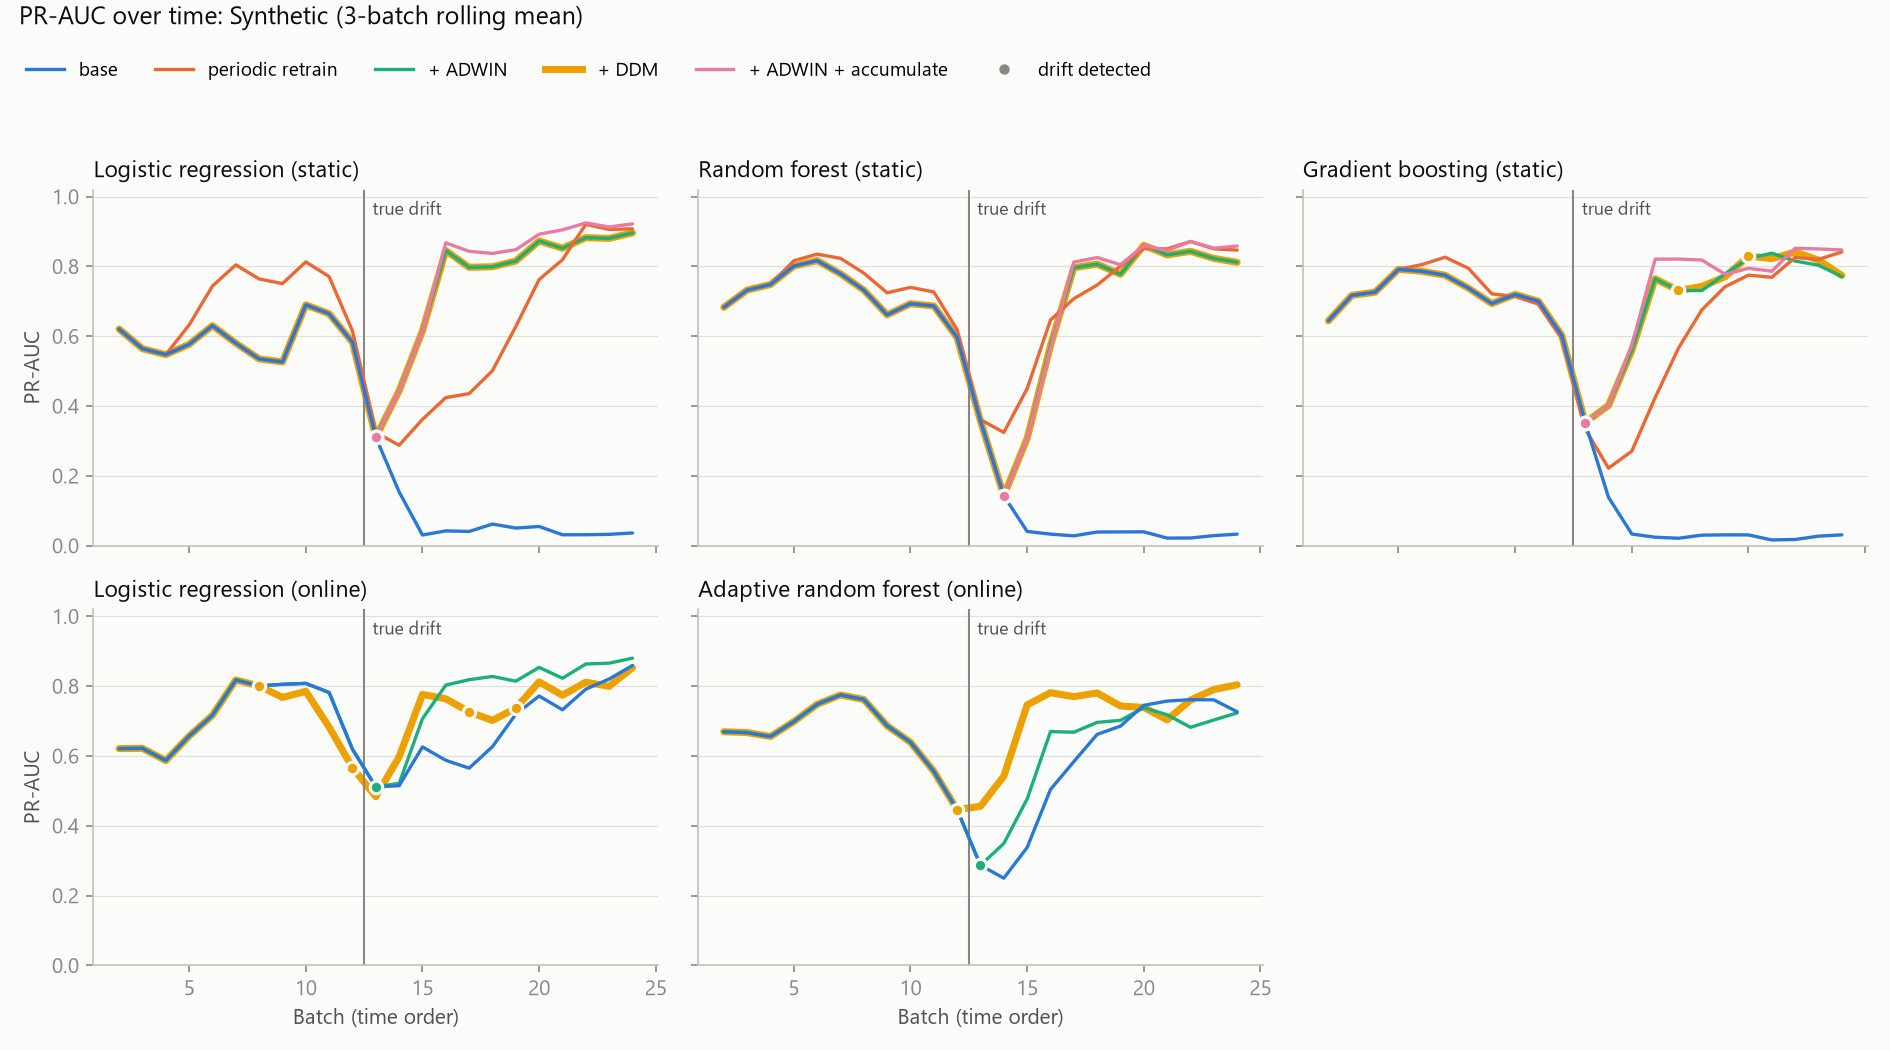

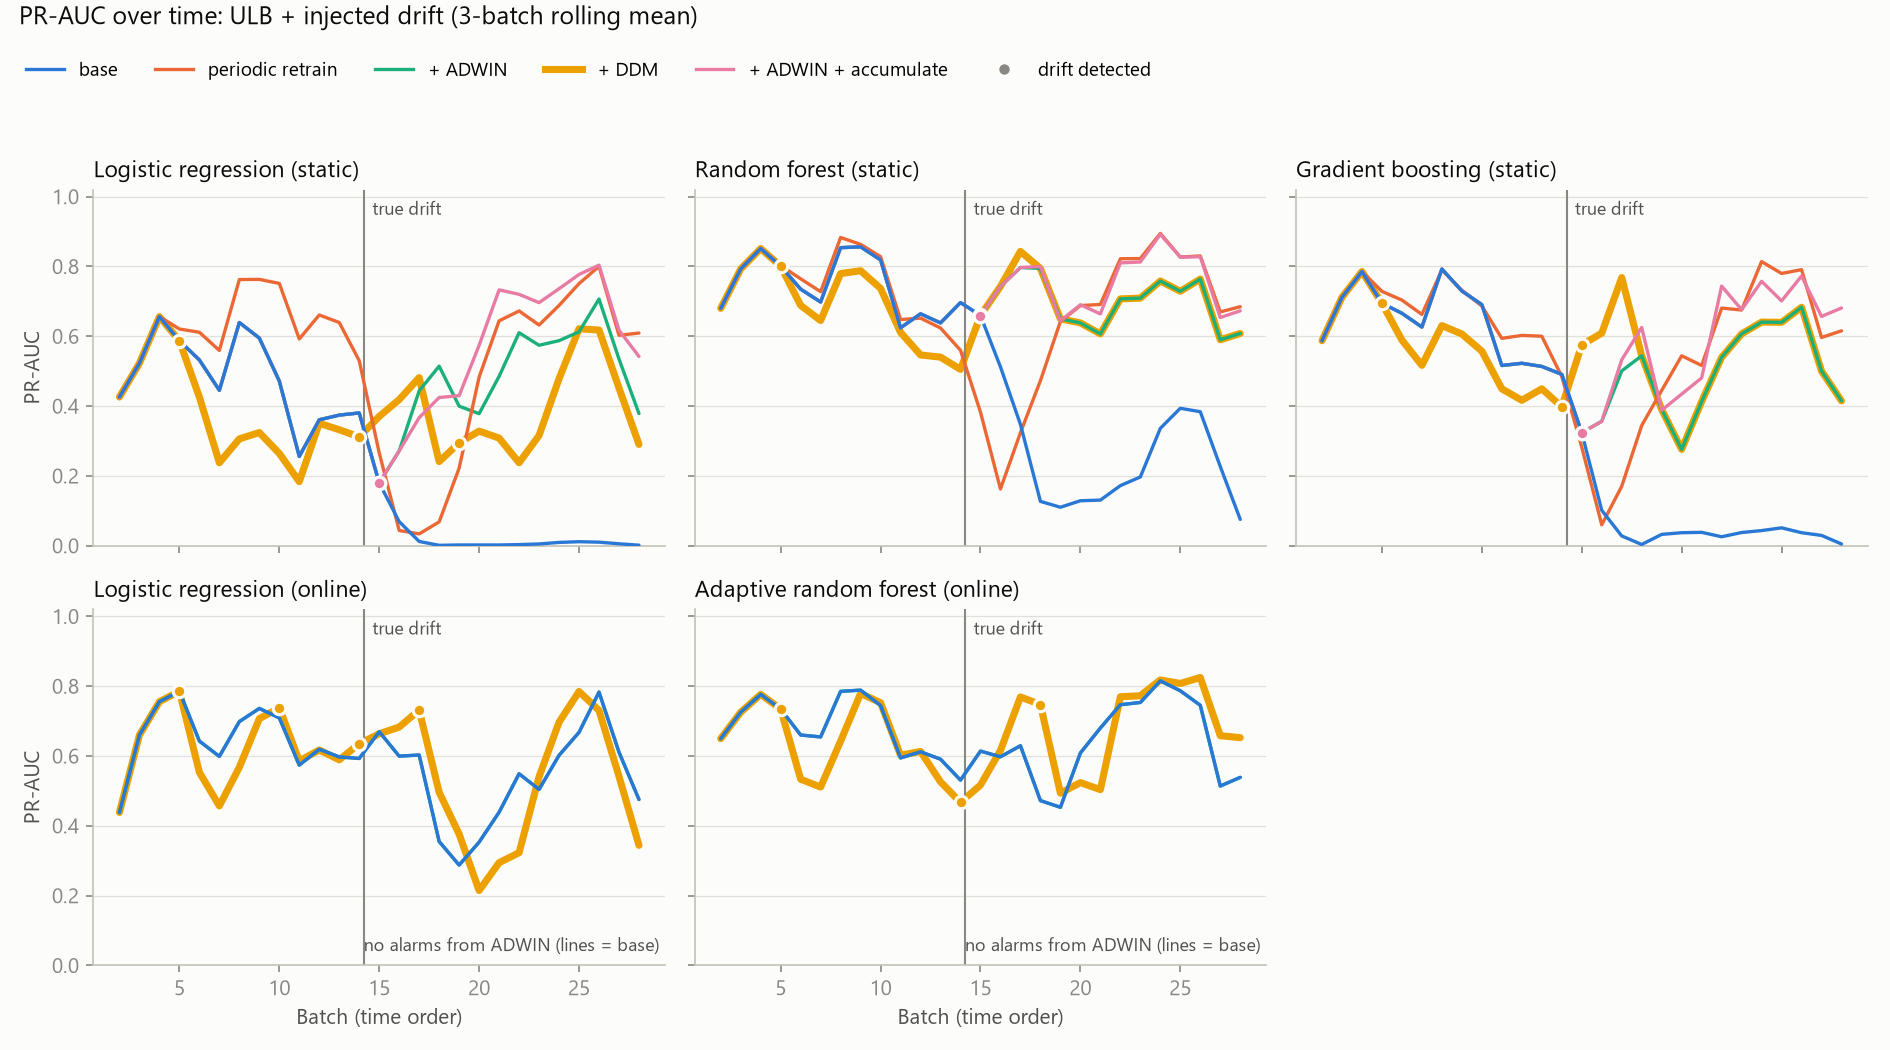

In [9]:
for tag in ["synthetic", "creditcard_drift50"]:
    summary, runs = data[tag]
    show(plot_metric_over_time, runs, metric="pr_auc", drift_batch=DATASETS[tag]["drift_batch"],
         title=f"PR-AUC over time: {DATASETS[tag]['label']} (3-batch rolling mean)")

### 2.3 How much performance is lost after the drift?

In [10]:
def response(tag, strategies):
    summary, runs = data[tag]
    table = drift_response_table(runs, DATASETS[tag]["drift_batch"]).merge(
        summary[["model_name", "family", "strategy"]], on="model_name")
    return table[table["strategy"].isin(strategies)]

cols = ["family", "strategy", "before", "after", "drop", "drop_pct", "worst_after"]
degradation = pd.concat({DATASETS[t]["label"]: response(t, ["base", "periodic retrain"])[cols].set_index(["family", "strategy"])
                         for t in ["synthetic", "creditcard_drift50"]}, names=["dataset"])
degradation.round(3)

before  after   drop  drop_pct  worst_after
dataset              family                          strategy                                                     
Synthetic            Logistic regression (static)    base               0.595  0.040  0.555    93.235        0.031
                                                     periodic retrain   0.712  0.648  0.065     9.079        0.010
                     Random forest (static)          base               0.734  0.034  0.700    95.385        0.022
                                                     periodic retrain   0.766  0.724  0.042     5.508        0.018
                     Gradient boosting (static)      base               0.733  0.028  0.705    96.189        0.017
                                                     periodic retrain   0.748  0.639  0.109    14.528        0.011
                     Logistic regression (online)    base               0.734  0.711  0.023     3.112        0.504
                     Adaptive random forest (online) base               0.672  0.621  0.051     7.568        0.095
ULB + injected drift Logistic regression (static)    base               0.487  0.007  0.480    98.652        0.001
                                                     periodic retrain   0.652  0.484  0.168    25.770        0.004
                     Random forest (static)          base               0.752  0.229  0.523    69.542        0.075
                                                     periodic retrain   0.758  0.654  0.104    13.756        0.110
                     Gradient boosting (static)      base               0.654  0.031  0.624    95.333        0.004
                                                     periodic retrain   0.684  0.541  0.143    20.925        0.002
                     Logistic regression (online)    base               0.665  0.524  0.142    21.291        0.288
                     Adaptive random forest (online) base               0.692  0.649  0.043     6.180        0.453

**Interpretation**

- **Static models lose almost everything after an abrupt drift:** −93% to −96% PR-AUC on synthetic data,
  −70% to −99% on ULB (random forest keeps the most, falling from 0.752 to 0.229).
- **Periodic retraining limits the loss** to −5% to −15% (synthetic) and −14% to −26% (ULB), but each periodic
  model still sinks to near zero right after the drift (worst rolling PR-AUC 0.002–0.110) until its next
  scheduled refits replace the old data.
- **Online models degrade least on synthetic data** (−3% and −8%) and moderately on ULB (−21% logistic
  regression, −6% adaptive random forest). Their dips are mostly shallower (worst 0.29–0.50; the adaptive forest on
  synthetic data is the exception at 0.10) because they learn from every transaction.
- So the order on both datasets is: static ≪ periodic retraining ≈ online, and the next section shows that
  drift-triggered strategies close most of the remaining gap.

### 2.4 ULB as recorded: is there slow decay without an injected drift?
Least-squares trend of per-batch PR-AUC (change per 10 batches, i.e. per ~17 hours of data).

In [11]:
summary, runs = data["creditcard"]
trend = runs.groupby("model_name").apply(trend_per_10_batches, include_groups=False).rename("PR-AUC trend per 10 batches")
trend = summary.set_index("model_name")[["strategy", "mean_pr_auc", "n_drift_flags"]].join(trend)
trend[trend["strategy"].isin(["base", "periodic retrain"])].round(3)

,strategy,mean_pr_auc,n_drift_flags,PR-AUC trend per 10 batches
model_name,,,,
logreg,base,0.429,0,-0.088
logreg_retrain3,periodic retrain,0.655,0,0.015
random_forest,base,0.760,0,-0.019
random_forest_retrain3,periodic retrain,0.760,0,-0.011
gradient_boosting,base,0.542,0,-0.127
gradient_boosting_retrain3,periodic retrain,0.681,0,-0.009
online_logreg,base,0.606,0,-0.060
online_arf,base,0.726,0,0.009


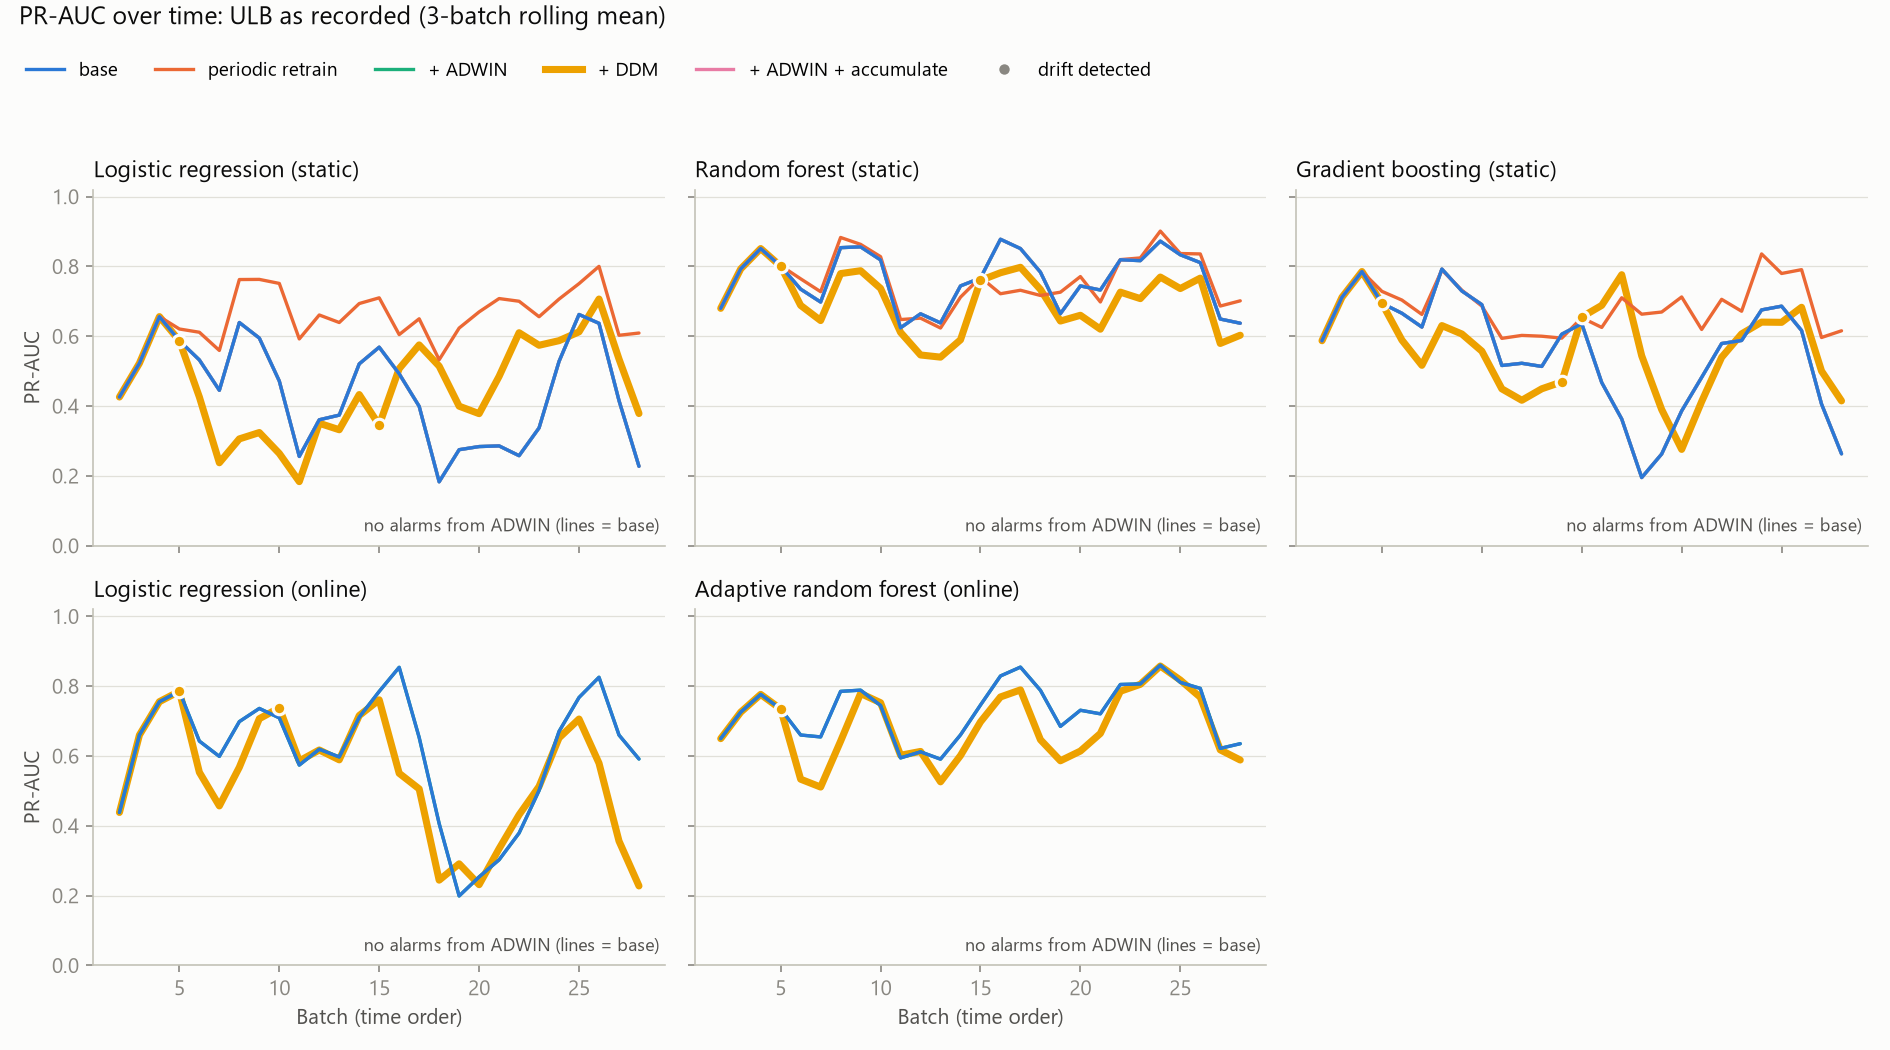

In [12]:
show(plot_metric_over_time, runs, metric="pr_auc", title="PR-AUC over time: ULB as recorded (3-batch rolling mean)")

**Interpretation**

- No abrupt drift was found in ULB as recorded: ADWIN never fired for any model.
- There is **mild gradual decline for the weaker static models**: −0.127 PR-AUC per 10 batches for gradient
  boosting and −0.088 for logistic regression, with only −0.019 for random forest. Periodic retraining removes
  it (−0.011 to +0.015) and lifts the mean PR-AUC of logistic regression from 0.429 to 0.655 and of gradient
  boosting from 0.542 to 0.681.
- This is consistent with small, gradual changes over the two days (or with the warm-up data being too little to
  generalise from). Either way, **gradual decline is invisible to an abrupt-change detector like ADWIN, while
  scheduled retraining handles it.** That's a useful complement to the injected-drift results.

## Objective 3: Drift detection and recovery

> *Integrate classical concept-drift detectors (ADWIN, DDM) that trigger adaptation upon distribution shift,
> and measure the resulting gain in minority-class recall and the model's recovery time after drift.*

### 3.1 When did the detectors fire?
An alarm before the drift (or on data with no known drift) is a false alarm. Detection delay = batches from the
batch in which the drift starts to the first alarm (0 = flagged in that same batch).

In [13]:
rows = []
for tag in DATASETS:
    summary, runs = data[tag]
    drift = DATASETS[tag]["drift_batch"]
    detected = summary[summary["strategy"].str.contains("ADWIN|DDM")]
    for _, s in detected.iterrows():
        alarms = runs.loc[(runs["model_name"] == s["model_name"]) & (runs["drift_flag"] == 1), "batch_idx"].tolist()
        row = {"dataset": DATASETS[tag]["label"], "model": s["model_name"], "detector": s["strategy"],
               "alarm batches": alarms}
        if drift is None:
            row["false alarms"] = len(alarms)
        else:
            after = [b for b in alarms if b >= math.floor(drift)]
            row["false alarms"] = len(alarms) - len(after)
            # 0 = flagged in the batch where the drift starts, 1 = in the next batch, ...
            row["detection delay (batches)"] = after[0] - math.floor(drift) if after else np.nan
        rows.append(row)
alarms = pd.DataFrame(rows)
alarms["detector"] = alarms["detector"].str.extract(r"(ADWIN|DDM)")[0]
alarms

,dataset,model,detector,alarm batches,false alarms,detection delay (batches)
0,Synthetic,logreg+adwin,ADWIN,[13],0,1.0
1,Synthetic,logreg+ddm,DDM,[13],0,1.0
2,Synthetic,logreg_acc6+adwin,ADWIN,[13],0,1.0
3,Synthetic,random_forest+adwin,ADWIN,[14],0,2.0
4,Synthetic,random_forest+ddm,DDM,[14],0,2.0
5,Synthetic,random_forest_acc6+adwin,ADWIN,[14],0,2.0
6,Synthetic,gradient_boosting+adwin,ADWIN,[13],0,1.0
7,Synthetic,gradient_boosting+ddm,DDM,"[13, 17, 20]",0,1.0
8,Synthetic,gradient_boosting_acc6+adwin,ADWIN,[13],0,1.0
9,Synthetic,online_logreg+adwin,ADWIN,[13],0,1.0


In [14]:
alarms.groupby(["dataset", "detector"]).agg(
    runs=("model", "size"),
    total_false_alarms=("false alarms", "sum"),
    runs_with_false_alarms=("false alarms", lambda s: int((s > 0).sum())),
    mean_detection_delay=("detection delay (batches)", "mean"),
    drifts_missed=("detection delay (batches)", lambda s: int(s.isna().sum())),
).round(2)

runs  total_false_alarms  runs_with_false_alarms  mean_detection_delay  drifts_missed
dataset              detector                                                                                       
Synthetic            ADWIN        8                   0                       0                  1.25              0
                     DDM          5                   1                       1                  0.80              0
ULB + injected drift ADWIN        8                   0                       0                  1.00              2
                     DDM          5                   6                       5                  0.20              0
ULB as recorded      ADWIN        8                   0                       0                   NaN              8
                     DDM          5                  10                       5                   NaN              5

**Interpretation**

- **ADWIN is precise.** It raised **zero false alarms** across all 24 runs on the three datasets, and caught every
  injected drift for the static models within one or two batches (mean delay 1.25 batches on synthetic, 1.0 on
  ULB). On ULB as recorded, where no drift was injected, it never fired at all.
- **DDM reacts faster but is trigger-happy.** It flags the drift sooner (often in the drift batch itself, mean
  delay 0.2 on ULB), but raises **6 false alarms on ULB with drift and 10 on ULB as recorded**. Its alarms
  cluster mostly at the same batches in every run (5 and 14–15), next to the two biggest fraud bursts in the stream
  (batches 4 and 15 hold 44 and 63 frauds; see the EDA notebook). A burst of missed frauds is enough to cross
  DDM's threshold.
- **ADWIN never fired for the online models on ULB** ("drifts missed: 2"). That's arguably correct behaviour, not
  a failure: those models adapt by themselves, so their error rate never jumped enough to count as a drift.

### 3.2 Gain in minority-class recall and PR-AUC after the drift
Mean over the batches after the drift; gain = strategy minus the frozen (`base`) version of the same static model.

In [15]:
rows = []
for tag in ["synthetic", "creditcard_drift50"]:
    summary, runs = data[tag]
    after = runs[runs["batch_idx"] >= DATASETS[tag]["drift_batch"]].groupby("model_name")[["recall_at_p", "pr_auc"]].mean()
    static = summary[summary["family"].str.contains("static")]
    for family, group in static.groupby("family", sort=False):
        base = after.loc[group.loc[group["strategy"] == "base", "model_name"].iloc[0]]
        for _, s in group.iterrows():
            a = after.loc[s["model_name"]]
            rows.append({"dataset": DATASETS[tag]["label"], "model": family.replace(" (static)", ""),
                         "strategy": s["strategy"],
                         "recall at 90% precision": a["recall_at_p"], "recall gain": a["recall_at_p"] - base["recall_at_p"],
                         "PR-AUC": a["pr_auc"], "PR-AUC gain": a["pr_auc"] - base["pr_auc"]})
gains = pd.DataFrame(rows)
gains.pivot_table(index=["dataset", "model"], columns="strategy", values="recall gain", sort=False)[
    ["periodic retrain", "+ ADWIN", "+ DDM", "+ ADWIN + accumulate"]].round(3)

strategy                                  periodic retrain  + ADWIN  + DDM  + ADWIN + accumulate
dataset              model                                                                      
Synthetic            Logistic regression             0.421    0.590  0.590                 0.688
                     Random forest                   0.417    0.482  0.482                 0.528
                     Gradient boosting               0.385    0.468  0.487                 0.536
ULB + injected drift Logistic regression             0.350    0.169  0.195                 0.384
                     Random forest                   0.567    0.526  0.573                 0.624
                     Gradient boosting               0.456    0.353  0.414                 0.492

In [16]:
gains.pivot_table(index=["dataset", "model"], columns="strategy", values="PR-AUC", sort=False)[
    ["base", "periodic retrain", "+ ADWIN", "+ DDM", "+ ADWIN + accumulate"]].round(3)

strategy                                   base  periodic retrain  + ADWIN  + DDM  + ADWIN + accumulate
dataset              model                                                                             
Synthetic            Logistic regression  0.040             0.648    0.791  0.791                 0.820
                     Random forest        0.034             0.724    0.690  0.690                 0.709
                     Gradient boosting    0.028             0.639    0.725  0.725                 0.757
ULB + injected drift Logistic regression  0.007             0.484    0.475  0.391                 0.575
                     Random forest        0.229             0.654    0.695  0.704                 0.750
                     Gradient boosting    0.031             0.541    0.486  0.543                 0.599

**Interpretation: gain in minority-class recall (objective 3)**

- **Every adaptive strategy raises recall after the drift**, and **accumulate-after-drift gives the largest recall
  gain in all 6 cases** (3 models × 2 datasets): +0.53 to +0.69 on synthetic data and +0.38 to +0.62 on ULB, over
  the frozen model.
- Plain `+ ADWIN` can do *worse* than periodic retraining on ULB (logistic regression recall gain +0.17 vs +0.35).
  It refits on one batch with ~17 frauds and then freezes, so the new model is underfed. Accumulating post-drift
  batches fixes exactly this.
- In PR-AUC after the drift, accumulate is best in 5 of 6 cases (e.g. ULB random forest 0.750 vs 0.695 single-batch
  ADWIN and 0.654 periodic). The exception is random forest on synthetic data, where periodic retraining is
  marginally ahead (0.724 vs 0.709).

### 3.3 Recovery time
Batches from the drift until the 3-batch rolling PR-AUC is back at 90% of the model's own pre-drift level,
after having fallen below it (0 = never fell below; NaN = never recovered). `batches below` counts all
post-drift batches spent under that level.

In [17]:
cols = ["family", "strategy", "before", "worst_after", "recovery_batches", "batches_below"]
recovery = pd.concat({DATASETS[t]["label"]: response(t, ["base", "periodic retrain", "+ ADWIN", "+ DDM", "+ ADWIN + accumulate"])[cols]
                      for t in ["synthetic", "creditcard_drift50"]}, names=["dataset"]).reset_index(level=0)
recovery.pivot_table(index=["dataset", "family"], columns="strategy", values="recovery_batches", sort=False)[
    ["base", "periodic retrain", "+ ADWIN", "+ DDM", "+ ADWIN + accumulate"]]

strategy                                              base  periodic retrain  + ADWIN  + DDM  + ADWIN + accumulate
dataset              family                                                                                       
Synthetic            Logistic regression (static)      NaN               7.0      2.0    2.0                   2.0
                     Random forest (static)            NaN               4.0      4.0    4.0                   4.0
                     Gradient boosting (static)        NaN               5.0      3.0    3.0                   3.0
                     Logistic regression (online)      6.0               NaN      2.0    1.0                   NaN
                     Adaptive random forest (online)   5.0               NaN      3.0    1.0                   NaN
ULB + injected drift Logistic regression (static)      NaN               6.0      2.0    9.0                   5.0
                     Random forest (static)            NaN               5.0      7.0    7.0                   5.0
                     Gradient boosting (static)        NaN               7.0      8.0    7.0                   3.0
                     Logistic regression (online)      9.0               NaN      9.0    9.0                   NaN
                     Adaptive random forest (online)   6.0               NaN      6.0    7.0                   NaN

In [18]:
recovery.pivot_table(index=["dataset", "family"], columns="strategy", values="batches_below", sort=False)[
    ["base", "periodic retrain", "+ ADWIN", "+ DDM", "+ ADWIN + accumulate"]]

strategy                                              base  periodic retrain  + ADWIN  + DDM  + ADWIN + accumulate
dataset              family                                                                                       
Synthetic            Logistic regression (static)     12.0               7.0      2.0    2.0                   2.0
                     Random forest (static)           12.0               4.0      4.0    4.0                   4.0
                     Gradient boosting (static)       12.0               5.0      3.0    3.0                   3.0
                     Logistic regression (online)      6.0               NaN      2.0    1.0                   NaN
                     Adaptive random forest (online)   5.0               NaN      3.0    1.0                   NaN
ULB + injected drift Logistic regression (static)     14.0               6.0      5.0    7.0                   5.0
                     Random forest (static)           13.0               6.0      5.0    3.0                   4.0
                     Gradient boosting (static)       14.0               8.0     10.0    5.0                   6.0
                     Logistic regression (online)      7.0               NaN      7.0    8.0                   NaN
                     Adaptive random forest (online)   5.0               NaN      5.0    3.0                   NaN

**Interpretation: recovery time (objective 3)**

- **Frozen static models never recover** (NaN), spending all 12–14 post-drift batches below their old level.
- **Accumulate-after-drift recovers fastest for random forest and gradient boosting on ULB** (5 and 3 batches, vs
  5–7 for periodic retraining and 7–8 for plain ADWIN), and on synthetic data in 2–4 batches, as fast as plain ADWIN.
  For logistic regression on ULB, plain ADWIN is back above target sooner (2 vs 5 batches) but then relapses: both
  spend 5 post-drift batches below target in total.
- **Plain ADWIN recovers quickly on synthetic data** but slowly on ULB (7–8 batches for random forest and
  gradient boosting); gradient boosting + ADWIN even recovers and then relapses (10 batches below target in total).
- **Periodic retraining is the slowest on synthetic data for logistic regression and gradient boosting** (7 and 5
  batches): it waits for its next scheduled refit and then still mixes old and new data in its window.
- **Online models need 5–9 batches** on their own; a detector shortens this on synthetic data (1–3 batches) but
  rarely fires for them on ULB.
- Caveat: recovery is measured against each model's *own* pre-drift level, so a model that was weak before the
  drift has an easier target (e.g. logistic regression + DDM, weakened by early false alarms).

### 3.4 Cost: how often does each strategy retrain, and how long does it take?

In [19]:
summary, runs = data["creditcard_drift50"]
n_batches = runs["batch_idx"].nunique()
refits = {"base": 0, "periodic retrain": n_batches // 3}
cost = summary[summary["family"].str.contains("static")][["family", "model_name", "strategy", "n_drift_flags", "runtime_s",
                                                          "mean_pr_auc_after_drift"]].copy()
cost["approx. refits"] = cost.apply(lambda s: refits.get(s["strategy"], s["n_drift_flags"] *
                                    (6 if "accumulate" in s["strategy"] else 1)), axis=1)
cost.pivot_table(index="family", columns="strategy", values=["approx. refits", "runtime_s"], sort=False).round(1)

approx. refits                                                     runtime_s                                                    
strategy                               base periodic retrain + ADWIN + DDM + ADWIN + accumulate      base periodic retrain + ADWIN + DDM + ADWIN + accumulate
family                                                                                                                                                       
Logistic regression (static)            0.0              9.0     1.0   3.0                  6.0       0.3              2.0     0.3   0.5                  1.0
Random forest (static)                  0.0              9.0     1.0   2.0                  6.0       2.0             29.3     2.6   3.1                 11.7
Gradient boosting (static)              0.0              9.0     1.0   3.0                  6.0       3.3             40.5     5.7  10.5                 22.0

**Interpretation**

Accumulate-after-drift needs about 6 refits after one alarm, against ~9 for periodic retraining, and ran in about
40–55% of periodic retraining's time for the tree models (random forest 11.7s vs 29.3s, gradient boosting 22.0s vs
40.5s). Between drifts it costs nothing. Single-batch ADWIN is the cheapest adaptive option (one refit) but recovers
less (section 3.2). Runtimes are from the run that produced these results and vary by machine; the ratios are what
matter.

## Synthesis

### What worked
| Finding | Evidence |
|---|---|
| Time-ordered (prequential) evaluation exposes decay that a one-off test score hides | Reported 0.67–0.89 vs deployed 0.004–0.069 after drift (2.1) |
| ADWIN is a precise drift alarm | 0 false alarms in 24 runs; every static-model drift caught in 1–2 batches (3.1) |
| **Accumulate-after-drift (our method)** is the best adaptation strategy | Largest recall gain in 6/6 cases, best PR-AUC in 5/6, fastest recovery for random forest and gradient boosting on ULB, ~half the cost of periodic retraining (3.2–3.4) |
| Handling imbalance on real data | Logistic regression 0.236 → 0.429–0.455; SMOTE lifts adaptive gradient boosting 0.455 → 0.696 (1.3) |
| Random forest as the base model | Best static baseline (0.760) and best overall with accumulate (0.750 after drift) |

### What didn't work, and why
| Finding | Why |
|---|---|
| DDM's false alarms | It reacts to short bursts of missed frauds, and each false alarm replaces a good model with one trained on a single batch |
| Single-batch drift retraining (plain `+ ADWIN`) can trail periodic retraining | One batch holds ~17 frauds: too little to learn the new pattern; fixed by accumulating |
| Drift detectors on online models | Online models adapt continuously, so their error rarely jumps enough to trigger ADWIN; little gain from adding one |
| Undersampling after drift | Discards data exactly when post-drift examples are scarce |
| Recall at 90% precision per batch | Often unreachable with ~13 frauds per batch and tied top scores; PR-AUC is the reliable headline |
| No natural drift in ULB | 48 hours is too short for fraud tactics to change; we inject drift (and IEEE-CIS remains the optional natural-drift check) |

### Conclusions by objective
1. **Objective 1:** classical baselines evaluated with imbalance-aware metrics work. Random forest reaches PR-AUC 0.760
   (440× random) with 63% recall at 90% precision and an FPR of 0.007%. Accuracy would have rated every model,
   including a useless one, above 99.8%.
2. **Objective 2:** under time-ordered evaluation, a static model loses 70–99% of its PR-AUC after an abrupt drift, while
   its pre-deployment test score stays high. Periodic retraining limits the loss to 5–26% and online learning to 3–21%.
3. **Objective 3:** ADWIN detects the drift within 1–2 batches without false alarms; DDM is faster but raises false alarms.
   Drift-triggered retraining recovers recall (gain up to +0.69), and accumulating post-drift data after the alarm gives
   the largest gains and the fastest recovery (3–5 batches on ULB) at roughly half the cost of periodic retraining.

### Limitations (details in `docs/IMPLEMENTATION_PLAN.md`)
- ULB's drift is **injected** and abrupt; natural or gradual drift (IEEE-CIS, robustness Task F) is not yet tested.
- Results come from **one seed**; differences of a few hundredths of PR-AUC between strategies are within noise.
- Labels are assumed to arrive immediately; in practice, fraud is confirmed days later.
- The drift signal watches missed frauds only; a drift that mainly raises false positives would go unnoticed.
- Recall at 90% precision uses a per-batch threshold chosen with that batch's labels: an upper bound on live performance.